# Hot Coffee

When you wrap your fingers around a ceramic mug filled with hot coffee, the mug will warm your hands, but the coffee will cool down quickly. In contrast, an insulated metal mug with an air layer is designed to prevent heat transfer, so it won't feel warm to the touch even if it contains scalding liquid. But will the coffee in this mug stay warm for a significantly longer period of time?

Let's also consider lids. How crucial is it to use a lid on an insulated cup to maintain the drink's temperature?

In the file `hot-coffee.csv`, we have data recording the temperature (in Fahrenheit) of initially hot coffee every 5 minutes in three types of cups:

- Insulated with a lid
- Insulated without a lid
- Ceramic without a lid

In [49]:
# FOR GOOGLE COLAB ONLY.
# Uncomment and run the code below. A dialog will appear to upload files.
# Upload 'hot-coffee.csv'.

# from google.colab import files
# uploaded = files.upload()

In [50]:
import math

import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import numpy as np


df = pd.read_csv('hot-coffee.csv')
df

,time,insulated with lid,insulated,ceramic
0,5,146.6,135.5,128.8
1,10,141.0,118.9,113.9
2,15,136.7,107.9,102.5
3,20,132.5,100.5,95.9
4,25,129.0,94.6,90.5
5,30,125.6,90.8,86.3
6,35,123.4,87.6,83.6
7,40,121.6,85.4,81.6
8,45,118.5,82.9,79.8
9,50,117.6,81.3,78.2


### Project Ideas:

- Create a line plot showing the temperature of the coffee in all three scenarios versus time. 

- Follow the Pro Tips for creating line plots.

- For comparison, consider adding a line representing the ambient air temperature, which was 67 degrees Fahrenheit.

Below is a helper function to label lines for your convenience.

In [51]:
def add_end_labels(df, x, column_names, alpha=1, fontweight='normal'):
    for column_name in column_names:
        y = df[column_name].iloc[-1]
        label = f'  {column_name}'
        plt.text(x, y, label, va="center", alpha=alpha, fontweight=fontweight)

In [52]:
# YOUR CODE HERE (add additional cells as needed)

T0 = 140.2 °F, k = 0.0236 pro Minute


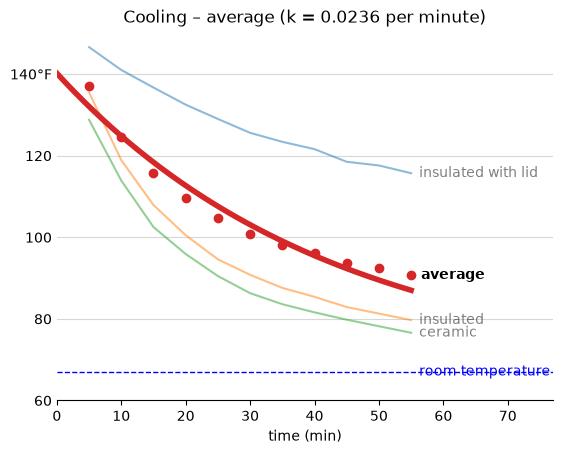

In [57]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Konfiguration
T_raum = 67
focus_column = 'average'
focus_color = 'C3'
back_columns = ['insulated with lid', 'insulated', 'ceramic']
back_colors = ['C0', 'C1', 'C2']

df['average'] = df[back_columns].mean(axis=1)
df = df.set_index('time')          # time als x-Achse, wie in der Vorlage

# Abkühlungsmodell
def abkuehlung(t, T0, k):
    return T_raum + (T0 - T_raum) * np.exp(-k * t)

(T0, k), _ = curve_fit(abkuehlung, df.index, df['average'], p0=(150, 0.01))
print(f'T0 = {T0:.1f} °F, k = {k:.4f} pro Minute')

# helper function
def add_end_labels(df, x, column_names, alpha=1, fontweight='normal'):
    for column_name in column_names:
        y = df[column_name].iloc[-1]
        label = f'  {column_name}'
        plt.text(x, y, label, va="center", alpha=alpha, fontweight=fontweight)

# plotting functions
def plot_data():
    df.plot(y=back_columns, color=back_colors, alpha=0.5)
    plt.plot(df.index, df[focus_column], 'o', color=focus_color)
    t_fein = np.linspace(0, df.index.max(), 200)
    plt.plot(t_fein, abkuehlung(t_fein, T0, k), color=focus_color, linewidth=4)
    plt.axhline(T_raum, color='b', linestyle='dashed', linewidth=1)

def label_lines():
    plt.legend().set_visible(False)
    x_ende = df.index[-1]
    add_end_labels(df, x_ende, back_columns, alpha=0.5)
    add_end_labels(df, x_ende, [focus_column], fontweight='bold')
    plt.text(x_ende, T_raum, '  room temperature', va='center', color='b')

def clean_axes():
    ax = plt.gca()
    ax.spines[['left', 'right', 'top']].set_visible(False)
    ax.tick_params(axis='y', length=0)
    plt.grid(axis='y', alpha=0.5)
    plt.xlim(0, df.index[-1] * 1.4)   # Platz für die Labels

def add_axes_labels():
    y_ticks = [60, 80, 100, 120, 140]
    y_tick_labels = ['60', '80', '100', '120', '140°F']
    plt.yticks(y_ticks, y_tick_labels)
    plt.xlabel('time (min)')
    plt.title(f'Cooling – average (k = {k:.4f} per minute)')

plot_data()
label_lines()
clean_axes()
add_axes_labels()
plt.show()